# Section 1 - Data Analysis

In [250]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


In [251]:
df = pd.read_csv("datasets/EVChargingStationUsage.csv")
df.head(2)

,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,3:03:32,1:54:03,...,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284.0,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,0:02:06,0:01:54,...,-122.160309,USD,0.0,Customer,4,94301.0,4169.0,NaN,NaN,NaN


## Datatypes and missing values

In [252]:
initial_length = len(df)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 259415 entries, 0 to 259414
Data columns (total 33 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Station Name                     259415 non-null  str    
 1   MAC Address                      259415 non-null  str    
 2   Org Name                         259415 non-null  str    
 3   Start Date                       259415 non-null  str    
 4   Start Time Zone                  259415 non-null  str    
 5   End Date                         259415 non-null  str    
 6   End Time Zone                    259415 non-null  str    
 7   Transaction Date (Pacific Time)  259206 non-null  str    
 8   Total Duration (hh:mm:ss)        259415 non-null  str    
 9   Charging Time (hh:mm:ss)         259415 non-null  str    
 10  Energy (kWh)                     259415 non-null  float64
 11  GHG Savings (kg)                 259415 non-null  float64
 12  Gasoline Savi

In [253]:
# standardize user ID
df["User ID"] = (
    df["User ID"]
    .astype("string")
    .str.strip()
    .str.replace(r"^(-?\d+)\.0$", r"\1", regex=True)
)

print(df['User ID'].nunique())

21441


In [254]:
# convert date columns to datetime format
df['Start Date'] = pd.to_datetime(df['Start Date'], errors = 'coerce')
df['End Date'] = pd.to_datetime(df['End Date'], errors = 'coerce')
df['Transaction Date (Pacific Time)'] = pd.to_datetime(df['Transaction Date (Pacific Time)'], errors='coerce')

# drop rows with invalid dates
n0 = len(df)
df = df.dropna(subset=['Start Date', 'End Date', 'Transaction Date (Pacific Time)'])
print(f"Dropped {len(df) - n0} rows with invalid or missing dates.")


Dropped -249 rows with invalid or missing dates.


In [255]:
# convert IDs and technical IDs into string
for col in ['EVSE ID', 'System S/N', 'Driver Postal Code', 'Postal Code']:
    df[col] = df[col].astype('Int64').astype('string')

**Check missing values**

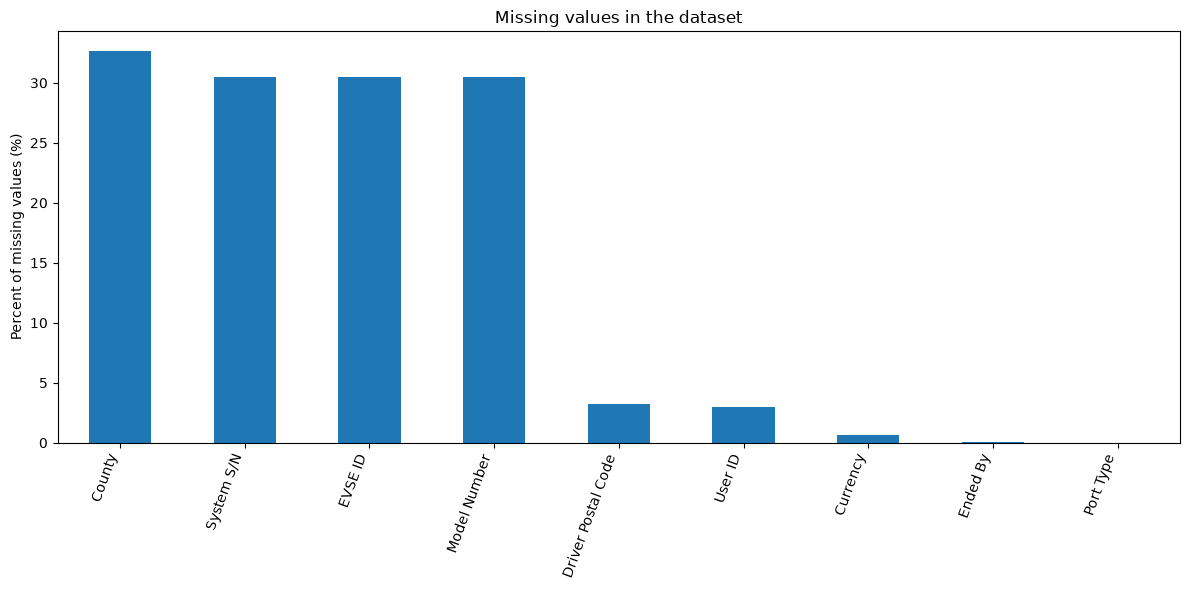

In [256]:
missing = (
    df.isna()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

missing = missing[missing > 0]
plt.figure(figsize=(12, 6))
missing.plot(kind="bar")
plt.ylabel("Percent of missing values (%)")
plt.title("Missing values in the dataset")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.show()

Several missing values - will be imputated by "missing" for categorical features

In [257]:
cat_cols = ['County', 'Model Number', 'User ID', 'Currency', 'Ended By', 'Port Type', 'EVSE ID', 'System S/N', 'Driver Postal Code', 'Postal Code']

for col in cat_cols:
    df[col] = df[col].astype('string').str.strip().fillna('missing')

print(df[cat_cols].isna().sum())

County                0
Model Number          0
User ID               0
Currency              0
Ended By              0
Port Type             0
EVSE ID               0
System S/N            0
Driver Postal Code    0
Postal Code           0
dtype: int64


### Handling Duration columns 

**Time Zone/Duration checks**

In [258]:
# we have 3 different time zones, so we add a new UTC column to verify the total duration 
print("Unique time zones:",df['Start Time Zone'].unique()) 
offsets = {
    "UTC": 0,
    "PST": -8,
    "PDT": -7
}

df["Start Date UTC"] = (
    df["Start Date"]
    - pd.to_timedelta(df["Start Time Zone"].map(offsets), unit="h")
)

df["End Date UTC"] = (
    df["End Date"]
    - pd.to_timedelta(df["End Time Zone"].map(offsets), unit="h")
)

df[['Start Date', 'Start Time Zone', 'Start Date UTC', 'End Date', 'End Time Zone', 'End Date UTC']].head(2)

Unique time zones: <StringArray>
['PDT', 'PST', 'UTC']
Length: 3, dtype: str


,Start Date,Start Time Zone,Start Date UTC,End Date,End Time Zone,End Date UTC
0,2011-07-29 20:17:00,PDT,2011-07-30 03:17:00,2011-07-29 23:20:00,PDT,2011-07-30 06:20:00
1,2011-07-30 00:00:00,PDT,2011-07-30 07:00:00,2011-07-30 00:02:00,PDT,2011-07-30 07:02:00


Drop columns where start date zone and end date zone are different, as they are likely to be incorrect.

In [259]:
n0 = len(df)
df = df[df['Start Time Zone'] == df['End Time Zone']]
print(f"Dropped {n0 - len(df)} rows where start and end time zones are different.")

Dropped 120 rows where start and end time zones are different.


**Total Duration column test**

Total duration should be End date - Start Date. We will test if that is consistent. If not, we will drop the Total Duration column and calculate it ourselves.

In [260]:
# duration from the original column (in seconds)
n0= len(df)
df["total_duration_sec"] = pd.to_timedelta(
    df["Total Duration (hh:mm:ss)"], errors="coerce"
).dt.total_seconds()

#duration calculated as End Date - Start date
df["timestamp_duration_sec"] = (
    df["End Date"] - df["Start Date"]
).dt.total_seconds()

#charging duration -> in seconds 
df["charging_duration_sec"] = pd.to_timedelta(
    df["Charging Time (hh:mm:ss)"], errors="coerce"
).dt.total_seconds()


# Compare Total Duration with duration calculated from timestamps
df["duration_diff_sec"] = (
    df["timestamp_duration_sec"] - df["total_duration_sec"]
).abs()

valid = df["duration_diff_sec"].notna()

print("Valid records:", valid.sum())
print("Exact matches:", (df.loc[valid, "duration_diff_sec"] == 0).sum())
print("Within 1 second:",
      (df.loc[valid, "duration_diff_sec"] <= 1).sum())
print("Within 10 seconds:",
      (df.loc[valid, "duration_diff_sec"] <= 10).sum())
print("Within 1 minute:",
      (df.loc[valid, "duration_diff_sec"] <= 60).sum())
print("Outside 1 minute:",
      (df.loc[valid, "duration_diff_sec"] > 60).sum())


# Remove records with missing duration values or differences greater than 1 minute
df = df[
    df["duration_diff_sec"].notna()
    & (df["duration_diff_sec"] <= 60)
].copy()

print("Records remaining after filtering:", len(df))
print("Removed : ", n0-len(df))


# Additional check : Since the total duration has 1 minute error, we make sure that charging duration
# is not longer than total duation
df["charging_duration_sec"] = df[
    ["charging_duration_sec", "total_duration_sec"]
].min(axis=1)


# Calculate duration columns in hours
df["total_duration_hours"] = df["total_duration_sec"] / 3600
df["charging_duration_hours"] = df["charging_duration_sec"] / 3600


# Add idle time columns = Total - charging
df["idle_seconds"] = (
    df["total_duration_sec"] - df["charging_duration_sec"]
)

df["idle_hours"] = df["idle_seconds"] / 3600


# Remove temporary checking columns
df.drop(
    columns=["timestamp_duration_sec", "duration_diff_sec"],
    inplace=True
)

df.head(1)


Valid records: 259046
Exact matches: 4328
Within 1 second: 12731
Within 10 seconds: 82717
Within 1 minute: 258699
Outside 1 minute: 347
Records remaining after filtering: 258699
Removed :  347


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,System S/N,Model Number,Start Date UTC,End Date UTC,total_duration_sec,charging_duration_sec,total_duration_hours,charging_duration_hours,idle_seconds,idle_hours
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-07-29 20:17:00,PDT,2011-07-29 23:20:00,PDT,2011-07-29 23:20:00,3:03:32,1:54:03,...,missing,missing,2011-07-30 03:17:00,2011-07-30 06:20:00,11012.0,6843.0,3.058889,1.900833,4169.0,1.158056


We see that the column is correct up to 1 min error tolerance. Therefore, we will keep it and only remove the inconsistent 347 records. (We will keep in mind that this can impose little differences while calculating durations directly from dates in the following tasks)

### Feature engineering and data cleaning

In [261]:
# add year, month, time of day etc
df["start_hour"] = df["Start Date"].dt.hour

conditions = [
    df["start_hour"].between(0, 5),
    df["start_hour"].between(6, 11),
    df["start_hour"].between(12, 17),
    df["start_hour"].between(18, 23)
]

labels = ["Night", "Morning", "Afternoon", "Evening"]

df["time_of_day"] = np.select(
    conditions,
    labels,
    default=None
)

df['year'] = df['Start Date'].dt.year
df['month'] = df['Start Date'].dt.month
df['day_of_week'] = df['Start Date'].dt.dayofweek  # 0 = Monday, 6 = Sunday


**Tests and removing incosistencies**

In [262]:
# check if we have any rows where the start date is after the end date
print("Number of rows with Start date UTC being later than End Date UTC: ",len(df[df['Start Date UTC']>df['End Date UTC']]))

Number of rows with Start date UTC being later than End Date UTC:  0


In [263]:
print("---------------------- Final Dataset Size after dropping inconsistent rows:--------------------------- ")
print(len(df))
print("Dropped in total :", initial_length - len(df), "rows, which is", (initial_length - len(df)) / initial_length * 100, "% of the original dataset.")
print("-----------------------Number of unique User ID (not missing)--------------------")
df_users = df[df['User ID']!= "missing"]
print(df_users['User ID'].nunique())

---------------------- Final Dataset Size after dropping inconsistent rows:--------------------------- 
258699
Dropped in total : 716 rows, which is 0.2760056280477228 % of the original dataset.
-----------------------Number of unique User ID (not missing)--------------------
21419


We dropped less than 1% of observations during cleaning, which is very little.

## EDA

In this part we do initial data analysis with a focus on durations, stations and port types.

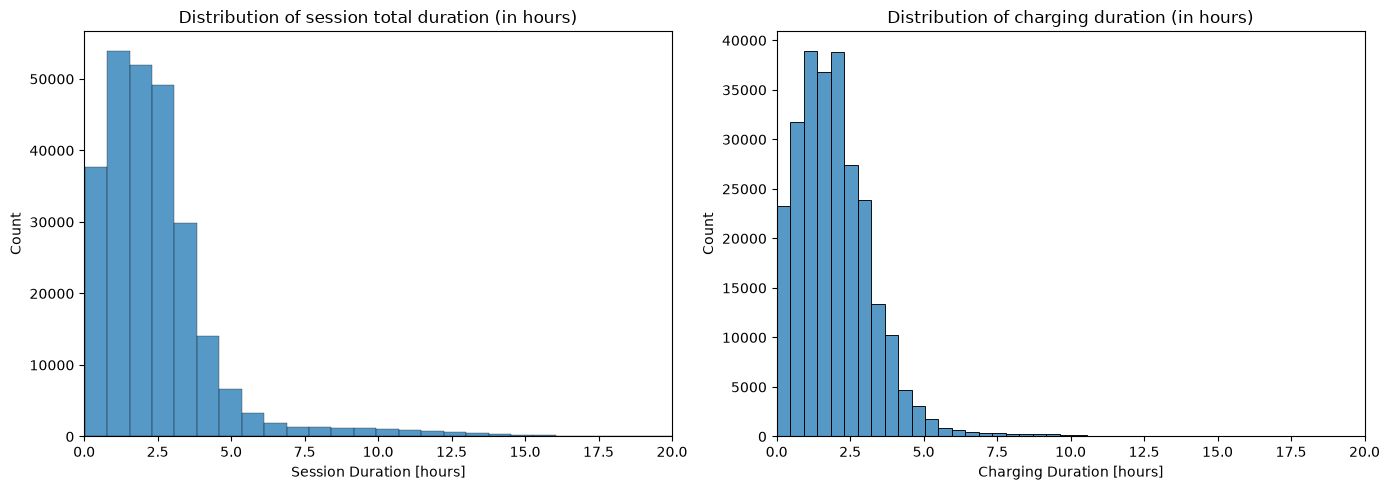

Charging time shorter by at least 15 min: 29.08%


In [264]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df, x="total_duration_hours",
    bins=150, ax=axes[0]
)
axes[0].set_title("Distribution of session total duration (in hours)")
axes[0].set_xlabel("Session Duration [hours]")

sns.histplot(
    data=df, x="charging_duration_hours",
    bins=50, ax=axes[1]
)
axes[1].set_title("Distribution of charging duration (in hours)")
axes[1].set_xlabel("Charging Duration [hours]")
axes[0].set_xlim(0, 20)
axes[1].set_xlim(0, 20)
plt.tight_layout()
plt.show()

valid = df[["charging_duration_hours", "total_duration_hours"]].dropna()
diff = valid["total_duration_hours"] - valid["charging_duration_hours"]
percent = (diff >= 15 / 60).mean() * 100

print(f"Charging time shorter by at least 15 min: {percent:.2f}%")

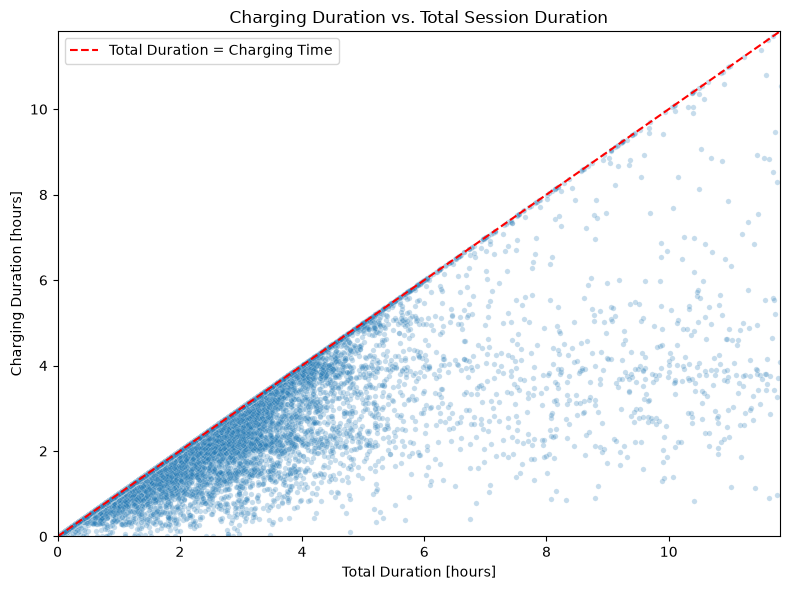

In [265]:
sample = df[
    ["total_duration_hours", "charging_duration_hours"]
].dropna()

if len(sample) > 20000:
    sample = sample.sample(20000, random_state=42)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=sample,
    x="total_duration_hours",
    y="charging_duration_hours",
    alpha=0.25,
    s=15
)

limit = sample[["total_duration_hours", "charging_duration_hours"]].quantile(0.99).max()
plt.plot([0, limit], [0, limit], "--", color="red",
         label="Total Duration = Charging Time")

plt.xlim(0, limit)
plt.ylim(0, limit)
plt.xlabel("Total Duration [hours]")
plt.ylabel("Charging Duration [hours]")
plt.title("Charging Duration vs. Total Session Duration")
plt.legend()
plt.tight_layout()
plt.show()

In [266]:
print("Average total duration (hours):", df["total_duration_hours"].mean())
print("Average charging duration (hours):", df["charging_duration_hours"].mean())

Average total duration (hours): 2.484551800011253
Average charging duration (hours): 1.998387563023694


Average charging duration is about 2h and total duration about 2.5h.

Idle time = 30 min is equal to 1/4 of the charging time.

## Stations analysis 

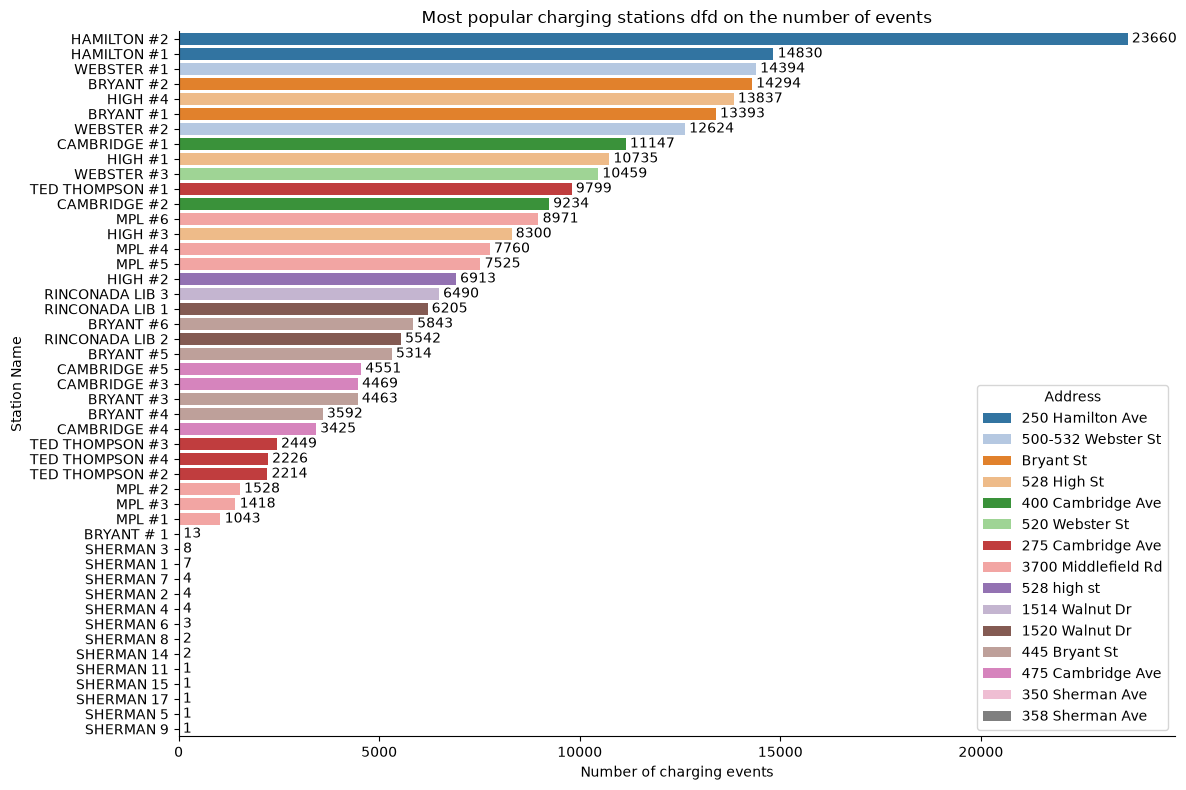

In [267]:
# plot most 'popular' stations dfd on the number of charging events
station_counts = (
    df.groupby("Station Name")
      .agg(
          n_events=("Station Name", "size"),
          address=("Address 1", "first")
      )
      .sort_values("n_events", ascending=False)
      .reset_index()
)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=station_counts,
    x="n_events",
    y="Station Name",
    hue="address",
    dodge=False,
    palette=sns.color_palette("tab20", n_colors=15)
)
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

labels = [label.get_text().replace("PALO ALTO CA / ", "") 
          for label in ax.get_yticklabels()]

ax.set_yticklabels(labels)
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xlabel("Number of charging events")
plt.ylabel("Station Name")
plt.title("Most popular charging stations dfd on the number of events")
plt.legend(title="Address")
plt.tight_layout()
plt.show()


In [268]:
top3 = (
    df.groupby(["year", "Station Name"])
      .size()
      .rename("n_events")
      .reset_index()
      .sort_values(["year", "n_events"], ascending=[True, False])
)
top3["rank"] = top3.groupby("year").cumcount() + 1
top3 = top3[top3["rank"] <= 3]
top3["Station Name"] = top3["Station Name"].str.replace("PALO ALTO CA / ", "", regex=False)
table = top3.pivot(index="year", columns="rank", values=["Station Name", "n_events"])
table.columns = [f"{'Station' if a == 'Station Name' else 'Events'} #{b}" for a, b in table.columns]
table = table[[f"{c} #{i}" for i in (1, 2, 3) for c in ("Station", "Events")]]   # parami: stacja, liczba

display(table)

,Station #1,Events #1,Station #2,Events #2,Station #3,Events #3
year,,,,,,
2011,HAMILTON #1,457,HAMILTON #2,396,HIGH #4,173
2012,HAMILTON #1,1407,HAMILTON #2,1371,BRYANT #2,1358
2013,BRYANT #2,2161,BRYANT #1,2116,HAMILTON #1,1988
2014,BRYANT #1,2505,BRYANT #2,2491,HIGH #4,2064
2015,BRYANT #2,2594,BRYANT #1,2412,HAMILTON #2,2061
2016,HAMILTON #2,3749,WEBSTER #1,3489,WEBSTER #2,3397
2017,HAMILTON #2,3513,WEBSTER #1,3191,CAMBRIDGE #1,3017
2018,HAMILTON #2,3429,WEBSTER #1,2644,WEBSTER #2,2157
2019,HAMILTON #2,3734,WEBSTER #1,2584,HIGH #3,2376


Hamilton, Bryant, Webster - the most overall events and leading in all years. Sherman - almost unused.

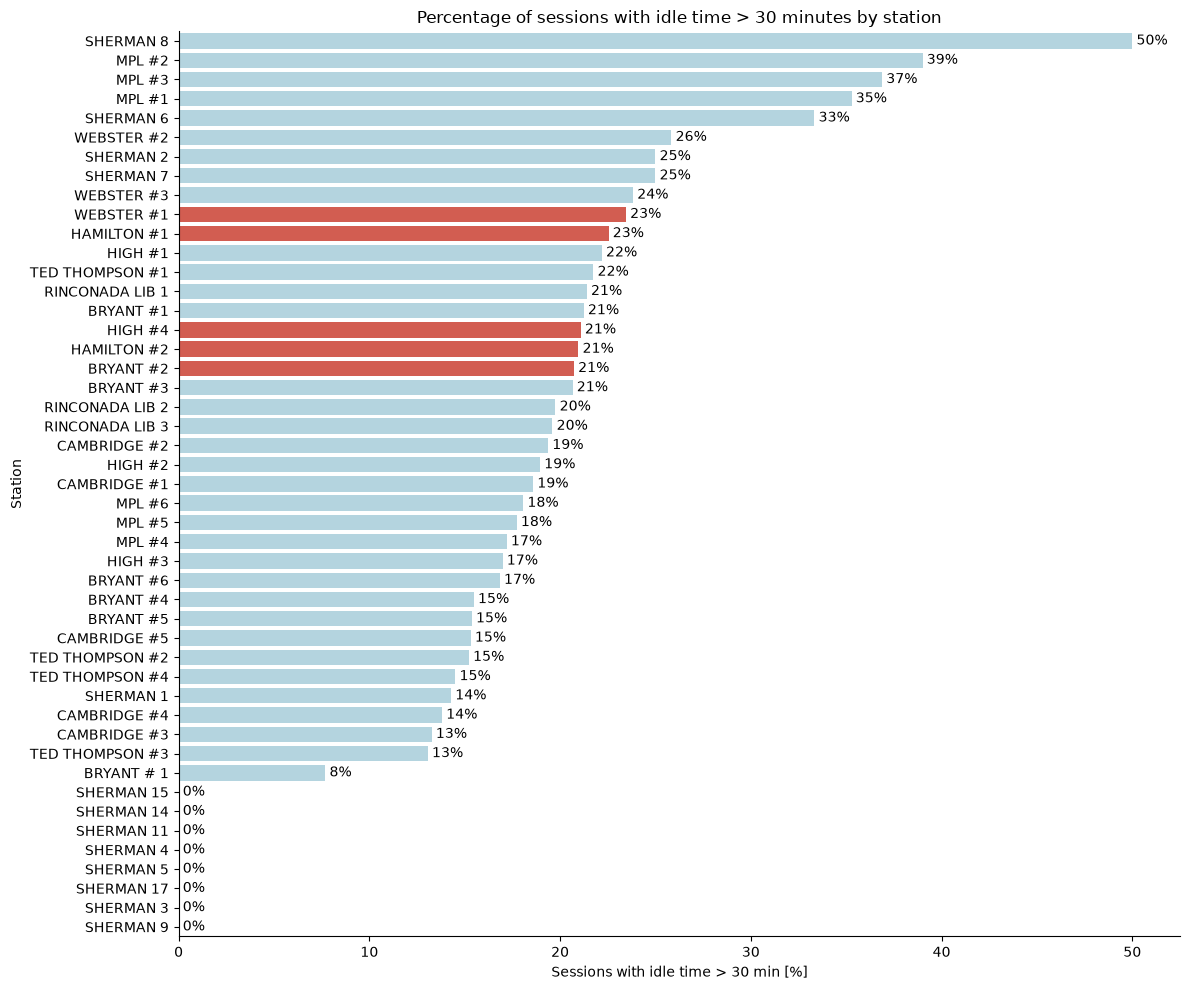

In [269]:
# plot the percentage of sessions with idle time greater than 20 minutes for each station
# highlighted most popular stations in red
idle_pct = (
    df.groupby("Station Name")["idle_hours"]
    .agg(
        total="count",
        above_30min=lambda x: (x > 30 / 60).sum()
    )
    .assign(percent=lambda x: 100 * x["above_30min"] / x["total"])
    .sort_values("percent", ascending=False)
)

highlight_stations = [
    "PALO ALTO CA / HAMILTON #1",
    "PALO ALTO CA / WEBSTER #1",
    "PALO ALTO CA / HAMILTON #2",
    "PALO ALTO CA / BRYANT #2",
    "PALO ALTO CA / HIGH #4",
]

plot_data = idle_pct.reset_index()
plot_data["color"] = plot_data["Station Name"].apply(
    lambda x: "Highlight" if x in highlight_stations else "Other"
)

palette = {"Highlight": "#e74c3c", "Other": "lightblue"}

fig, ax = plt.subplots(figsize=(12, 10))

sns.barplot(
    data=plot_data,
    x="percent",
    y="Station Name",
    hue="color",
    palette=palette,
    dodge=False,
    legend=False,
    ax=ax
)
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", padding=3)
labels = [
    label.get_text().replace("PALO ALTO CA / ", "")
    for label in ax.get_yticklabels()
]
ax.set_yticklabels(labels)

ax.set_xlabel("Sessions with idle time > 30 min [%]")
ax.set_ylabel("Station")
ax.set_title("Percentage of sessions with idle time > 30 minutes by station")

sns.despine()
plt.tight_layout()
plt.show()

Sherman/MPL with a high percentage (is also due to a low number of events). The top 5 most popular stations have the % of events with idle time>30 min at around 20%, which is quite high.

## Port type analysis

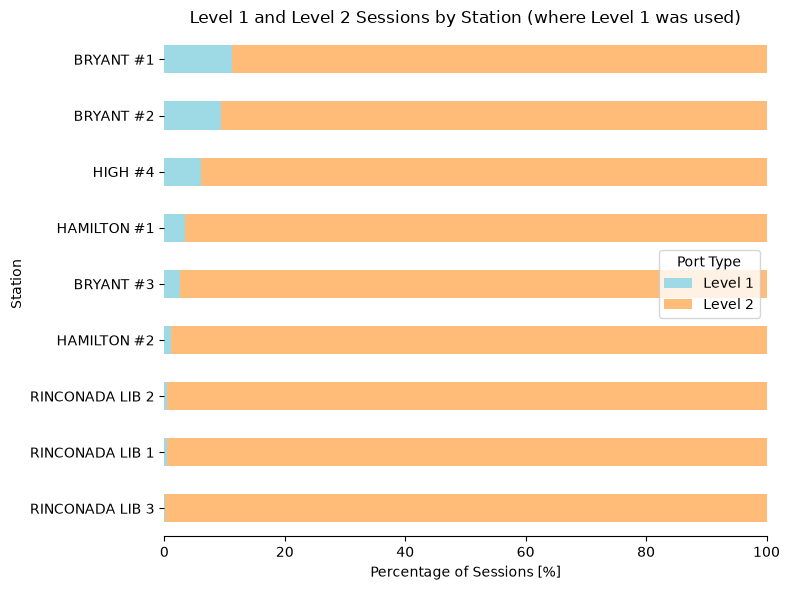

In [270]:
# Stations where at least one Level 1 session occurred
stations_level1 = df.loc[
    df["Port Type"] == "Level 1", "Station Name"
].unique()

df_levels = df[
    df["Station Name"].isin(stations_level1)
    & df["Port Type"].isin(["Level 1", "Level 2"])
].copy()

level_pct = pd.crosstab(
    df_levels["Station Name"],
    df_levels["Port Type"],
    normalize="index"
) * 100

level_pct = level_pct.reindex(
    columns=["Level 1", "Level 2"], fill_value=0
).sort_values("Level 2", ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))

level_pct.plot(
    kind="barh",
    stacked=True,
    color=["#9edae5", "#ffbb78"],
    ax=ax
)

labels = [
    label.get_text().replace("PALO ALTO CA / ", "")
    for label in ax.get_yticklabels()
]
ax.set_yticklabels(labels)

ax.set_xlabel("Percentage of Sessions [%]")
ax.set_ylabel("Station")
ax.set_title("Level 1 and Level 2 Sessions by Station (where Level 1 was used)")
ax.legend(title="Port Type")
ax.set_xlim(0, 100)


sns.despine(ax=ax)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

Port Type = Level 1 was only used at 9 stations, and the % of events with Level1 are less than 20% on each station.

## Durations deeper-dive

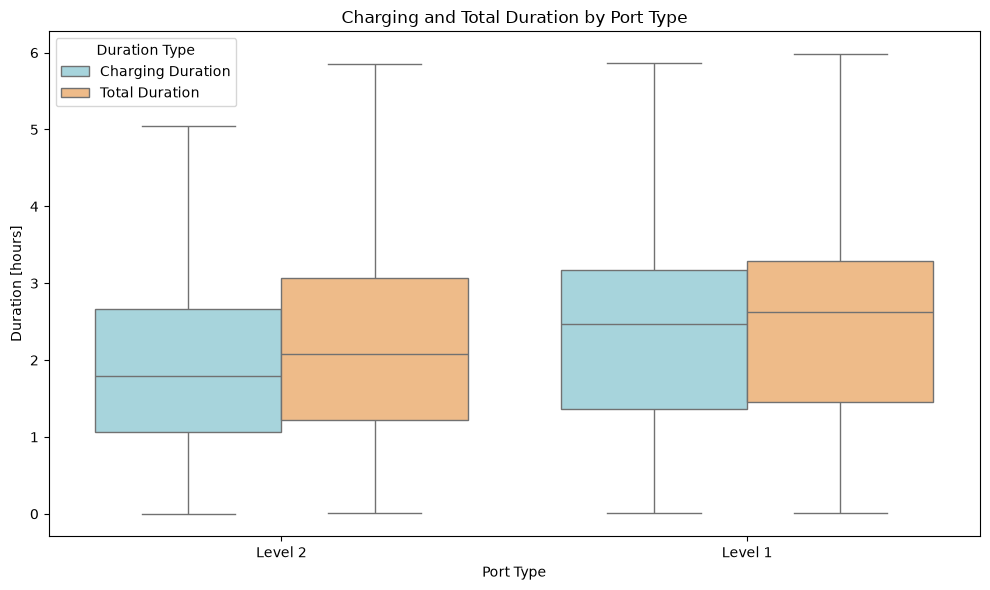

In [271]:
# plot the distribution of charging/total duration for Level 1 and Level 2 sessions
df_plot = df_levels.melt(
    id_vars="Port Type",
    value_vars=["charging_duration_hours", "total_duration_hours"],
    var_name="Duration Type",
    value_name="Duration [hours]"
)

df_plot["Duration Type"] = df_plot["Duration Type"].map({
    "charging_duration_hours": "Charging Duration",
    "total_duration_hours": "Total Duration"
})

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_plot,
    x="Port Type",
    y="Duration [hours]",
    hue="Duration Type",
    showfliers=False,
    palette=["#9edae5", "#ffbb78"]
)

plt.xlabel("Port Type")
plt.ylabel("Duration [hours]")
plt.title("Charging and Total Duration by Port Type")
plt.legend(title="Duration Type")
plt.tight_layout()
plt.show()

Level 1 is a slower port type; the differences in total duration vs charging duration are bigger for Level2.

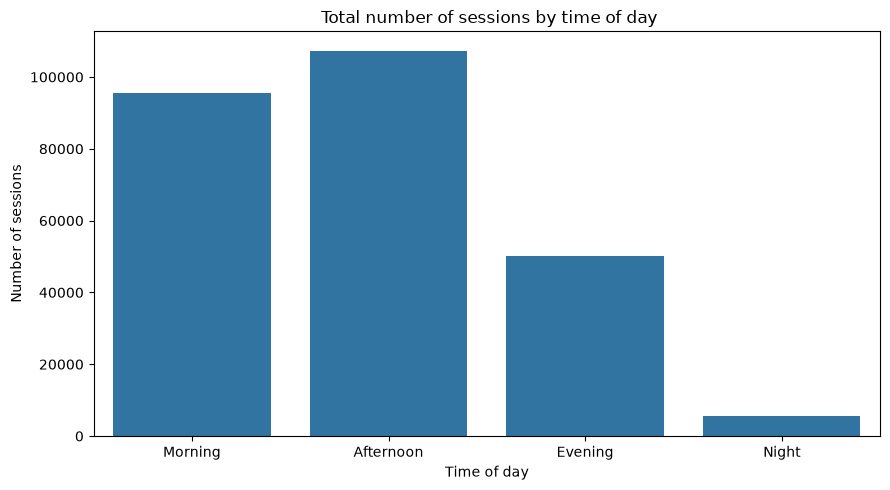

In [272]:
# plot the number of sessions by time of day
order = [ "Morning", "Afternoon", "Evening", "Night"]

plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="time_of_day",
    order=order,
    legend=False
)

plt.xlabel("Time of day")
plt.ylabel("Number of sessions")
plt.title(" Total number of sessions by time of day")
plt.tight_layout()
plt.show()

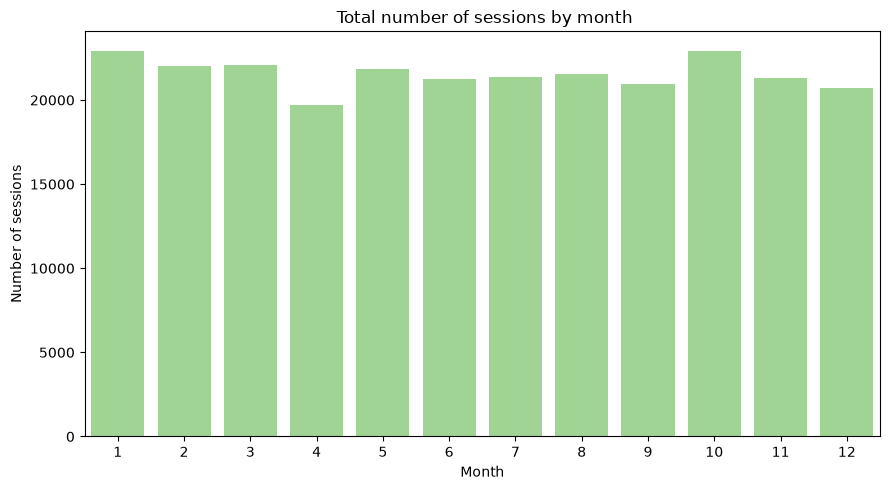

In [273]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="month",
    color="#98df8a",
    legend=False
)

plt.xlabel("Month")
plt.ylabel("Number of sessions")
plt.title(" Total number of sessions by month")
plt.tight_layout()
plt.show()

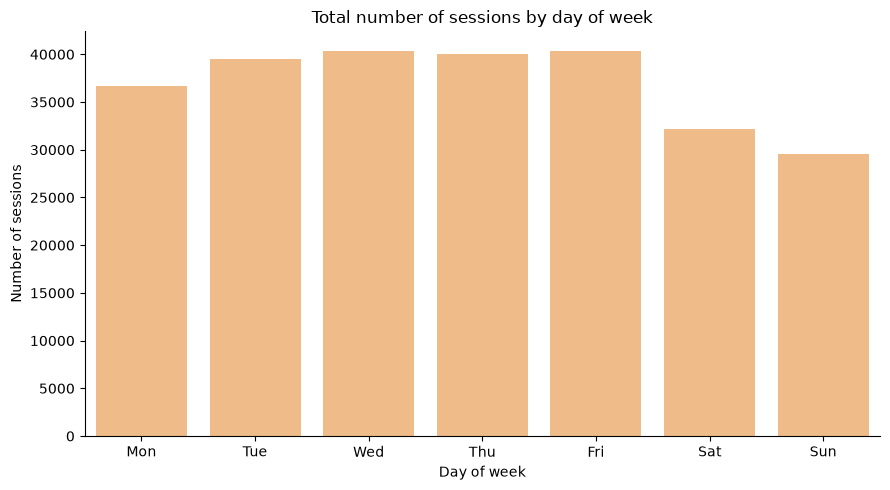

In [274]:
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.figure(figsize=(9, 5))
ax = sns.countplot(
    data=df,
    x="day_of_week",
    order=range(7),         
    color="#ffbb78"
)

ax.set_xticks(range(7))
ax.set_xticklabels(day_names)
ax.spines[["top", "right"]].set_visible(False)

plt.xlabel("Day of week")
plt.ylabel("Number of sessions")
plt.title("Total number of sessions by day of week")
plt.tight_layout()
plt.show()

The highest charging traffic happens in the morning and afternoon and on the weekdays.

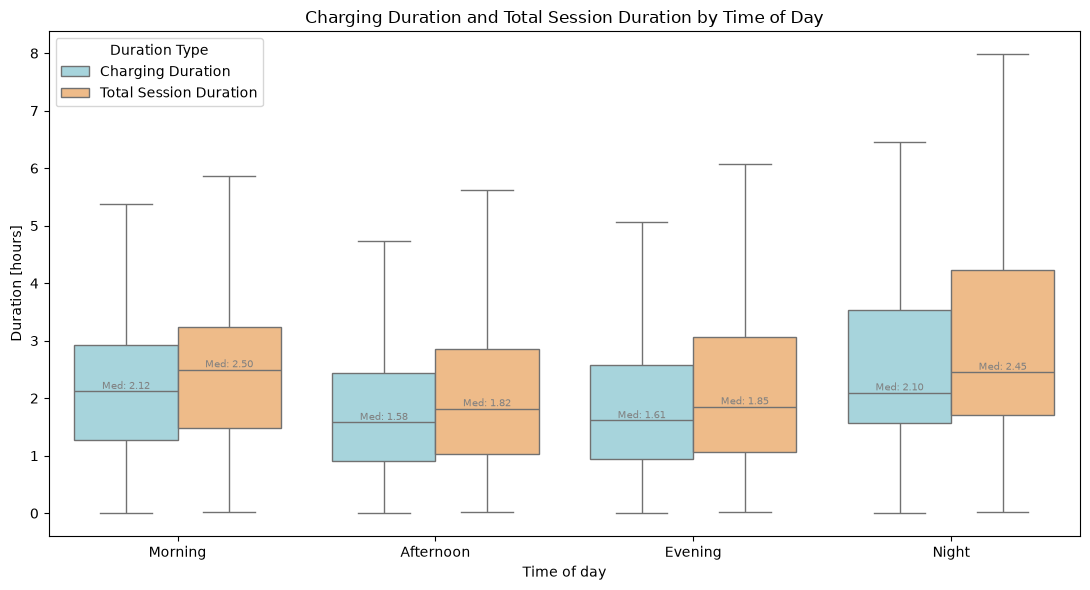

In [275]:
# plot the distribution of charging / total duration for each time of day
df_plot = df.melt(
    id_vars="time_of_day",
    value_vars=["charging_duration_hours", "total_duration_hours"],
    var_name="Duration Type",
    value_name="Duration [hours]"
)

df_plot["Duration Type"] = df_plot["Duration Type"].map({
    "charging_duration_hours": "Charging Duration",
    "total_duration_hours": "Total Session Duration"
})

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df_plot,
    x="time_of_day",
    y="Duration [hours]",
    order=order,
    hue="Duration Type",
    palette=["#9edae5", "#ffbb78"],
    showfliers=False
)

plt.xlabel("Time of day")
plt.ylabel("Duration [hours]")
plt.title("Charging Duration and Total Session Duration by Time of Day")
plt.legend(title="Duration Type")
# Add Q1, median and Q3 labels
stats = (
    df_plot.groupby(["time_of_day", "Duration Type"])["Duration [hours]"]
    .quantile([0.25, 0.5, 0.75])
    .unstack()
)
n_hue = 2
offsets = [-0.2, 0.2]

for i, tod in enumerate(order):
    for j, duration_type in enumerate(["Charging Duration", "Total Session Duration"]):
        if (tod, duration_type) not in stats.index:
            continue

        q1, median, q3 = stats.loc[(tod, duration_type)].values
        x = i + offsets[j]

        ax = plt.gca()
        ax.text(x, median, f"Med: {median:.2f}",
                ha="center", va="bottom", fontsize=7, color='gray')
plt.tight_layout()
plt.show()

The highest charging and total times are observed in the morning and night. At night there are some outliers reaching up to 8h of total duration (the spread is also the greatest at night). The biggest difference in Medians between charging and total time is 0.38 (Mornings).

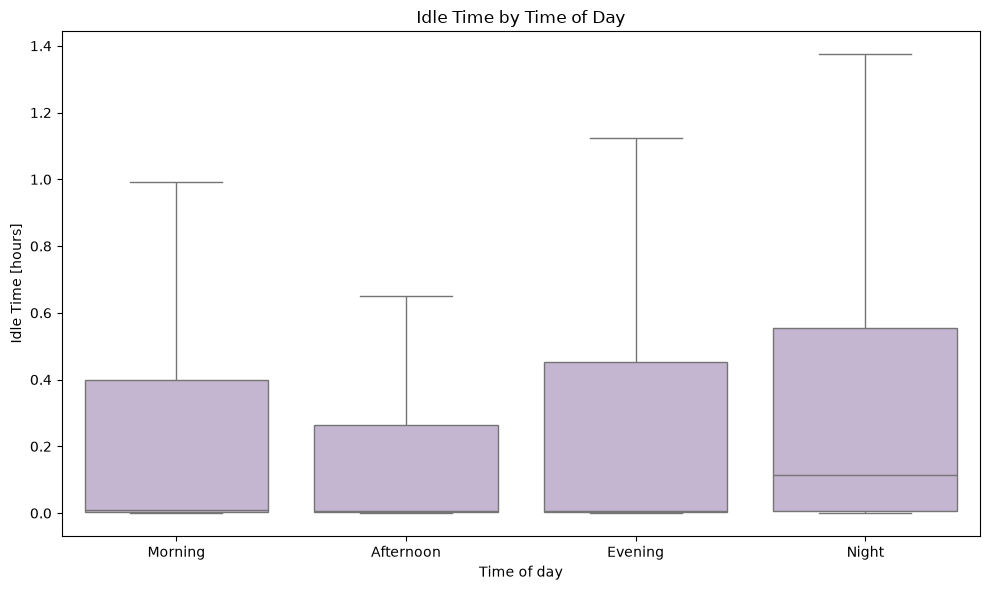

In [276]:
# Idle time analysis by time of day
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df[df["idle_hours"] >= 0],
    x="time_of_day",
    y="idle_hours",
    order=order,
    color="#c5b0d5",
    showfliers=False,
    legend=False
)

plt.xlabel("Time of day")
plt.ylabel("Idle Time [hours]")
plt.title("Idle Time by Time of Day")
plt.tight_layout()
plt.show()

At night idle times are the highest (up to 1.4h) with median areound 0.1h

## Time Analysis

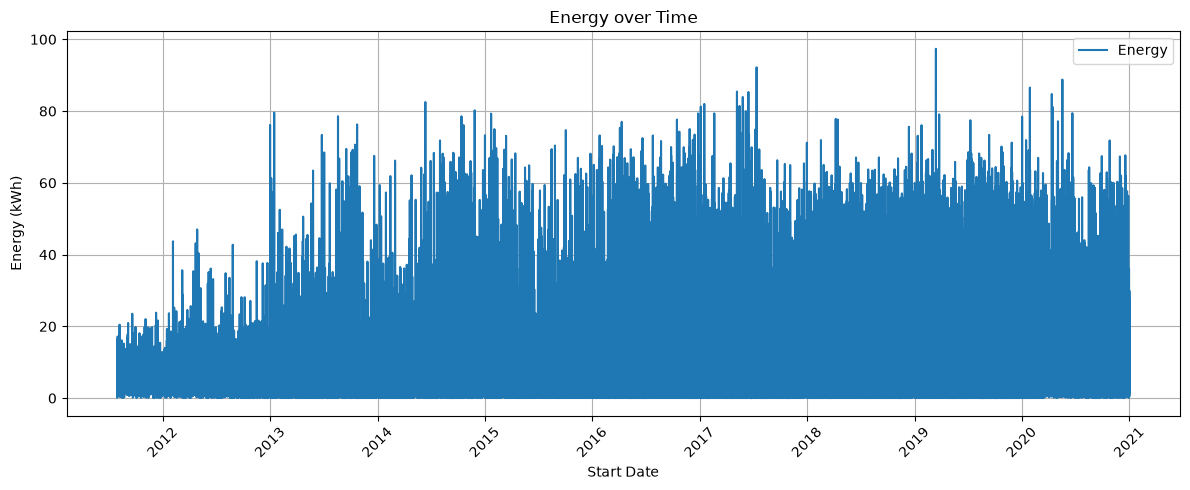

In [277]:
df = df.sort_values("Start Date")
plt.figure(figsize=(12, 5))
plt.plot(df["Start Date"], df["Energy (kWh)"], label="Energy")

plt.xlabel("Start Date")
plt.ylabel("Energy (kWh)")
plt.title("Energy over Time")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

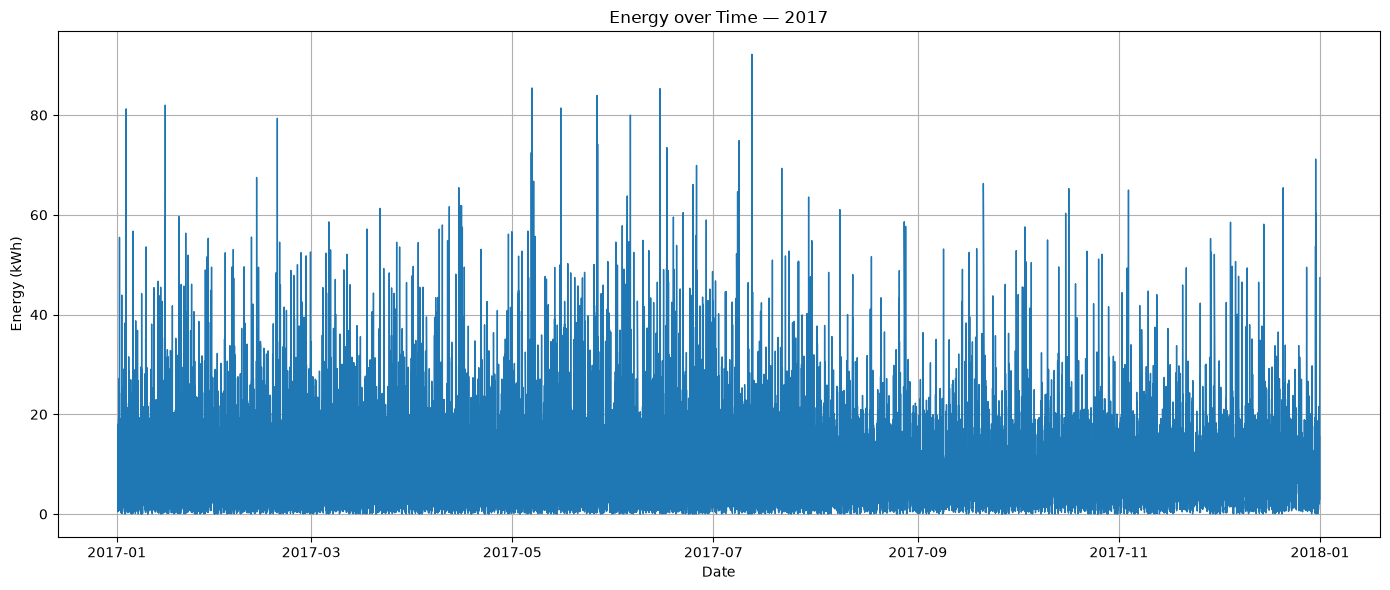

In [278]:
# zoom closer on a selected month
year = 2017
df_year = df[df["Start Date"].dt.year == year].copy()

df_year = df_year.sort_values("Start Date")
plt.figure(figsize=(14, 6))
plt.plot(df_year["Start Date"], df_year["Energy (kWh)"], linewidth=1)

plt.xlabel("Date")
plt.ylabel("Energy (kWh)")
plt.title(f"Energy over Time — {year}")
plt.grid(True)
plt.tight_layout()
plt.show()

Energy usage increased after 2013. Visible peaks and drops throughout the years.

<span style="color:green"> --------------------------------Hourly Grouping ideas---------------------</span>

### Idea 1 - for Clustering tasks

**Preprocessing step1**: split each session into 1 hour intervals with energy usage proportional (to the charging time not occupation time).

Example:

Raw data : Start time Monday 20:17, End Time Monday 23:20, Charging Time = 1:54, Total Time = 3:03, Energy = 6.4 (here End of charging = 20:17 + 1h 54 min = 22:11)

Split the total CHARGING time into each start hour :

20 -> 43 min (20:17 - 21:00)= 2580s 

21 -> 1h (21:00-22:00): 3600 s

22 -> 11min (22:00-22:11) : 660s

23-> 0 min : 0s

But total charging time was 1h54 min : 6840s (will be used to calculate energy usage)

| User ID | Station | Start Hour | Energy (kWh) | Charging time | Occupation time | Idle time |
| ------- | ------- | ---------- | ------------ | ------------- | --------------- | --------- |
| U1 | S1 | 20 | 6.4 * (2580/6840) = 2.41 | 43 min = 0.72 h | 43 min = 0.72 h | 0 |
| U1 | S1 | 21 | 6.4 * (3600/6840) = 3.37 | 1 h | 1 h | 0 |
| U1 | S1 | 22 | 6.4 * (660/6840) = 0.62 | 11 min = 0.18 h | 1 h | 0.82 h |
| U1 | S1 | 23 | 0 | 0 | 20 min = 0.33 h | 0.33 h |

**Preprocessing step2**: Add some columns about datetime : so time of day, day of the week, month

**Final aggregation**:
One row = 1 user 

Columns : 

- share_energy_morning, share_energy_afternoon ... , share_energy_monday: share of the user's total energy in each time block / weekday ( from hourly table).
- share_sessions_*: share of the user's sessions *started* in each time block. This is counted on the raw data (1 row = 1 session)
- idle_ratio: idle hours / occupied hours (how much of the plug-in time the user holds the station without charging).
- avg_charging_duration 
- avg_session_duraton
- avg_energy_per_session






In [279]:
# code for idea 1

#step 1 - create hourly_events from raw data

df_task1 = df.copy().reset_index(drop=True)

df_task1["session_id"] = df_task1.index


hourly_rows = []

for _, row in df_task1.iterrows():

    start = row["Start Date"]
    end = row["End Date"]

    charging_duration = row["charging_duration_sec"]
    total_energy = row["Energy (kWh)"]

    total_occupied_seconds = (end - start).total_seconds()

    # Assumption: charging starts when the vehicle is plugged in
    # and continues without interruption
    charging_end = start + pd.Timedelta(seconds=charging_duration)

    # First hourly interval
    current_hour = start.floor("h")

    while current_hour < end:

        next_hour = current_hour + pd.Timedelta(hours=1)

        # Calculate occupation time within this hour
        occupied_start = max(start, current_hour)
        occupied_end = min(end, next_hour)

        occupied_seconds = (
            occupied_end - occupied_start
        ).total_seconds()

        # Calculate active charging time within this hour
        charging_start_overlap = max(start, current_hour)
        charging_end_overlap = min(charging_end, next_hour)

        charging_seconds = max(
            0,
            (charging_end_overlap - charging_start_overlap).total_seconds()
        )

        # Calculate idle time
        idle_seconds = occupied_seconds - charging_seconds

        # Allocate energy proportionally to charging time
        if charging_duration > 0:
            energy_kwh = (
                total_energy * charging_seconds / charging_duration
            )
        else:
            energy_kwh = 0

        hourly_rows.append({
            "session_id": row["session_id"],
            "User ID": row["User ID"],
            "Station Name": row["Station Name"],
            "hour": current_hour,
            "energy_kwh": energy_kwh,
            "charging_hours": charging_seconds / 3600,
            "occupied_hours": occupied_seconds / 3600,
            "idle_hours": idle_seconds / 3600
        })

        current_hour = next_hour


hourly_events = pd.DataFrame(hourly_rows)
hourly_events.head(10)


,session_id,User ID,Station Name,hour,energy_kwh,charging_hours,occupied_hours,idle_hours
0,0,3284,PALO ALTO CA / HAMILTON #1,2011-07-29 20:00:00,2.356218,0.716667,0.716667,0.000000
1,0,3284,PALO ALTO CA / HAMILTON #1,2011-07-29 21:00:00,3.287746,1.000000,1.000000,0.000000
2,0,3284,PALO ALTO CA / HAMILTON #1,2011-07-29 22:00:00,0.605493,0.184167,1.000000,0.815833
3,0,3284,PALO ALTO CA / HAMILTON #1,2011-07-29 23:00:00,0.000000,0.000000,0.333333,0.333333
4,1,4169,PALO ALTO CA / HAMILTON #1,2011-07-30 00:00:00,0.106588,0.031667,0.033333,0.001667
5,2,4169,PALO ALTO CA / HAMILTON #1,2011-07-30 08:00:00,2.555198,0.733333,0.733333,0.000000
6,2,4169,PALO ALTO CA / HAMILTON #1,2011-07-30 09:00:00,3.484360,1.000000,1.000000,0.000000
7,2,4169,PALO ALTO CA / HAMILTON #1,2011-07-30 10:00:00,3.484360,1.000000,1.000000,0.000000
8,2,4169,PALO ALTO CA / HAMILTON #1,2011-07-30 11:00:00,3.484360,1.000000,1.000000,0.000000
9,2,4169,PALO ALTO CA / HAMILTON #1,2011-07-30 12:00:00,1.943499,0.557778,0.566667,0.008889


Sanity check:

In [280]:
# Expected number of hourly intervals for each session
df_task1["expected_hours"] = (
    (
        df_task1["End Date"] - pd.Timedelta(nanoseconds=1)
    ).dt.floor("h")
    - df_task1["Start Date"].dt.floor("h")
).dt.total_seconds() / 3600 + 1

# Actual number of rows for each session in hourly_events
actual_hours = (
    hourly_events.groupby("session_id")
    .size()
    .rename("actual_hours")
)


hours_check = (
    df_task1.set_index("session_id")[["expected_hours"]]
    .join(actual_hours)
)

hours_check["actual_hours"] = hours_check["actual_hours"].fillna(0)

print("Sessions with incorrect number of hourly rows:",
      (hours_check["expected_hours"] != hours_check["actual_hours"]).sum())

Sessions with incorrect number of hourly rows: 0


In [281]:
print(df['Energy (kWh)'].sum())
print(hourly_events['energy_kwh'].sum())

print(df['total_duration_hours'].sum())
print(hourly_events['occupied_hours'].sum())

2209897.51953
2209882.8875371004
642751.0661111111
642725.2833333333


A little difference in total energy -> can be a reason of differences in Total duration vs End Date - Start Date (as shown by the difference in total duration hours vs occupied hours)

In [282]:
# step 2 - final aggregation

hourly_events["day_of_week"] = hourly_events["hour"].dt.dayofweek
hourly_events["hour_of_day"] = hourly_events["hour"].dt.hour

hourly_events["is_weekend"] = (
    hourly_events["day_of_week"] >= 5
).astype(int)

conditions = [
    hourly_events["hour_of_day"].between(0, 5),
    hourly_events["hour_of_day"].between(6, 11),
    hourly_events["hour_of_day"].between(12, 17),
    hourly_events["hour_of_day"].between(18, 23)
]

labels = ["Night", "Morning", "Afternoon", "Evening"]
hourly_events["time_of_day"] = np.select(
    conditions,
    labels,
    default=None
)

In [283]:
# Total energy and occupation per user
user_totals = hourly_events.groupby("User ID").agg(
    total_energy_kwh=("energy_kwh", "sum"),
    total_occupied_hours=("occupied_hours", "sum"),
    total_charging_hours=("charging_hours", "sum"),
    total_idle_hours=("idle_hours", "sum")
)

# Energy by time of day
energy_by_time = (
    hourly_events.groupby(["User ID", "time_of_day"])["energy_kwh"]
    .sum()
    .unstack(fill_value=0)
    .reindex(
        columns=["Night", "Morning", "Afternoon", "Evening"],
        fill_value=0
    )
)

energy_by_time.columns = [
    "energy_night",
    "energy_morning",
    "energy_afternoon",
    "energy_evening"
]


# Energy by day of week
energy_by_day = (
    hourly_events.groupby(["User ID", "day_of_week"])["energy_kwh"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=range(7), fill_value=0)
)

energy_by_day.columns = [
    "energy_monday",
    "energy_tuesday",
    "energy_wednesday",
    "energy_thursday",
    "energy_friday",
    "energy_saturday",
    "energy_sunday"
]

occupation_weekend = (
    hourly_events[hourly_events["is_weekend"] == 1]
    .groupby("User ID")["occupied_hours"]
    .sum()
    .rename("occupation_weekend")
)


user_features = (
    user_totals
    .join(energy_by_day)
    .join(energy_by_time)
    .join(occupation_weekend)
    .fillna(0)
)

# calculate shares instead of total values

days = [
    "monday", "tuesday", "wednesday",
    "thursday", "friday", "saturday", "sunday"
]

for day in days:
    user_features[f"share_energy_{day}"] = (
        user_features[f"energy_{day}"] /
        user_features["total_energy_kwh"].replace(0, np.nan)
    )


periods = ["night", "morning", "afternoon", "evening"]

for period in periods:
    user_features[f"share_energy_{period}"] = (
        user_features[f"energy_{period}"] /
        user_features["total_energy_kwh"].replace(0, np.nan)
    )

user_features["share_occupation_weekend"] = (
    user_features["occupation_weekend"] /
    user_features["total_occupied_hours"].replace(0, np.nan)
)

user_features

,total_energy_kwh,total_occupied_hours,total_charging_hours,total_idle_hours,energy_monday,energy_tuesday,energy_wednesday,energy_thursday,energy_friday,energy_saturday,...,share_energy_wednesday,share_energy_thursday,share_energy_friday,share_energy_saturday,share_energy_sunday,share_energy_night,share_energy_morning,share_energy_afternoon,share_energy_evening,share_occupation_weekend
User ID,,,,,,,,,,,,,,,,,,,,,
0,3074.786229,1231.666667,909.348333,322.318333,380.922016,494.404088,517.074505,536.602517,562.743706,370.639556,...,0.168166,0.174517,0.183019,0.120542,0.069078,0.051380,0.238961,0.320503,0.389157,0.202382
1000031,4.959000,3.616667,1.763056,1.853611,0.000000,4.959000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
1000311,13.430000,2.400000,2.404444,-0.004444,0.000000,0.000000,0.000000,0.000000,13.430000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
100061V,34.569000,9.333333,5.896389,3.436944,0.000000,14.300000,0.000000,15.016000,5.253000,0.000000,...,0.000000,0.434378,0.151957,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
10013,11.177250,2.616667,2.604167,0.012500,2.263000,0.000000,1.708250,0.000000,7.206000,0.000000,...,0.152833,0.000000,0.644702,0.000000,0.000000,0.000000,0.000000,0.355298,0.644702,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99823,14.409335,5.233333,4.872500,0.360833,0.000000,12.548339,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.129152,0.000000,0.129152,0.247977,0.622871,0.181529
998481,12.360000,2.850000,2.278611,0.571389,0.000000,0.000000,12.360000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
998781,6.201000,1.900000,1.889444,0.010556,0.000000,0.000000,0.000000,6.201000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000


### Idea 2 - TO DO

# Section 2 - Mandatory components

## Clustering 

In [284]:
# TO DO

## Prediction model

In [285]:
# TO DO

# Section 3 - Exploratory component

In [286]:
# TO DO